In [ ]:
import sys
import platform
import importlib.util

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Operating system:", platform.platform())

packages = ["torch", "torchvision", "numpy", "pandas", "sklearn", "PIL"]

print("\nInstalled packages:")
for package in packages:
    print(f"{package}:",
          "Installed" if importlib.util.find_spec(package) else "Missing")

try:
    import torch
    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU memory (GB):",
              round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
except ImportError:
    print("\nPyTorch is not installed yet.")

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Python executable: /usr/bin/python3
Operating system: Linux-6.6.122+-x86_64-with-glibc2.39

Installed packages:
torch: Installed
torchvision: Installed
numpy: Installed
pandas: Installed
sklearn: Installed
PIL: Installed

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [ ]:
from google.colab import files

uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

print("Uploaded ZIP files:", zip_files)

Saving polymercode-classification-dataset (3).zip to polymercode-classification-dataset (3).zip
Uploaded ZIP files: ['polymercode-classification-dataset (3).zip']


In [ ]:
from pathlib import Path
import zipfile

zip_name = next(
    (name for name in uploaded if name.endswith(".zip")),
    None
)

assert zip_name is not None, "Please upload the dataset ZIP first."

data_dir = Path("PolymerCode-AI/data/classification_dataset")
data_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(data_dir)

print("Dataset extracted to:", data_dir.resolve())
print("\nTop-level contents:")

for item in sorted(data_dir.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)

Dataset extracted to: /content/PolymerCode-AI/data/classification_dataset

Top-level contents:
📁 classification_dataset


In [ ]:
from pathlib import Path
import pandas as pd

# Find the extracted classification dataset
matches = [
    p for p in Path(".").rglob("metadata.csv")
    if all((p.parent / split).is_dir()
           for split in ["train", "val", "test"])
]

if not matches:
    raise FileNotFoundError(
        "Dataset not found. Upload and extract the ZIP first."
    )

DATA_DIR = matches[0].parent
print("Dataset location:", DATA_DIR.resolve())

# Count images in each split and class
extensions = {".jpg", ".jpeg", ".png", ".webp"}
rows = []

for split in ["train", "val", "test"]:
    for folder in sorted((DATA_DIR / split).iterdir()):
        if folder.is_dir():
            count = sum(
                1 for f in folder.iterdir()
                if f.is_file() and f.suffix.lower() in extensions
            )
            rows.append({
                "Split": split,
                "Class": folder.name,
                "Images": count
            })

counts = pd.DataFrame(rows)
print("\nImage counts:")
display(counts.pivot(
    index="Class", columns="Split",
    values="Images"
).fillna(0).astype(int))

print("\nTotal images:", int(counts["Images"].sum()))

metadata = pd.read_csv(DATA_DIR / "metadata.csv")
print("Metadata records:", len(metadata))
print("\nDataset audit:")
display(metadata[[
    "source_image", "new_split",
    "class_name", "resin_code"
]].head())

Dataset location: /content/PolymerCode-AI/data/classification_dataset/classification_dataset

Image counts:


Split,test,train,val
Class,,,
HDPE,9,51,9
LDPE,15,58,15
OTHER,11,42,9
PET,15,74,15
PP,24,114,24
PS,4,21,6
PVC,3,14,3



Total images: 536
Metadata records: 536

Dataset audit:


,source_image,new_split,class_name,resin_code
0,train/images/00bfb003-97c9-4329-bd55-c54a12811...,train,OTHER,7
1,train/images/30b14a3f-487a-4f19-80b1-f24ddb072...,train,PS,6
2,train/images/85943598-ec9b-4da5-9221-8c32b5742...,val,PET,1
3,train/images/BBOZ2526_jpg.rf.aa065d4735f4db7b2...,train,PET,1
4,train/images/BMOY1981_jpg.rf.063246b2fd1e24b79...,train,OTHER,7


In [ ]:
from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

# Check whether crops from one original image cross splits
md = metadata.copy()

md["source_key"] = (
    md["source_image"]
    .astype(str)
    .str.replace("\\", "/", regex=False)
    .str.rsplit("/", n=1)
    .str[-1]
    .str.rsplit(".", n=1)
    .str[0]
)

source_split_counts = md.groupby("source_key")["new_split"].nunique()
cross_split_sources = source_split_counts[source_split_counts > 1]

print("Unique original source images:", md["source_key"].nunique())
print("Sources appearing in multiple splits:", len(cross_split_sources))

if len(cross_split_sources):
    display(
        md[md["source_key"].isin(cross_split_sources.index)]
        [["source_image", "new_split", "class_name"]]
        .sort_values("source_image")
        .head(30)
    )
else:
    print("No source-image overlap detected across splits.")

# Check exact duplicate image contents across splits
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}
hash_to_splits = defaultdict(set)
hash_to_files = defaultdict(list)

for split in ["train", "val", "test"]:
    split_dir = DATA_DIR / split

    for path in split_dir.rglob("*"):
        if path.is_file() and path.suffix.lower() in image_extensions:
            digest = hashlib.sha256(path.read_bytes()).hexdigest()
            hash_to_splits[digest].add(split)
            hash_to_files[digest].append(str(path))

cross_split_hashes = {
    digest: files
    for digest, files in hash_to_files.items()
    if len(hash_to_splits[digest]) > 1
}

print("\nExact duplicate images across splits:", len(cross_split_hashes))

for files in list(cross_split_hashes.values())[:10]:
    print(files)


Unique original source images: 536
Sources appearing in multiple splits: 0
No source-image overlap detected across splits.

Exact duplicate images across splits: 0


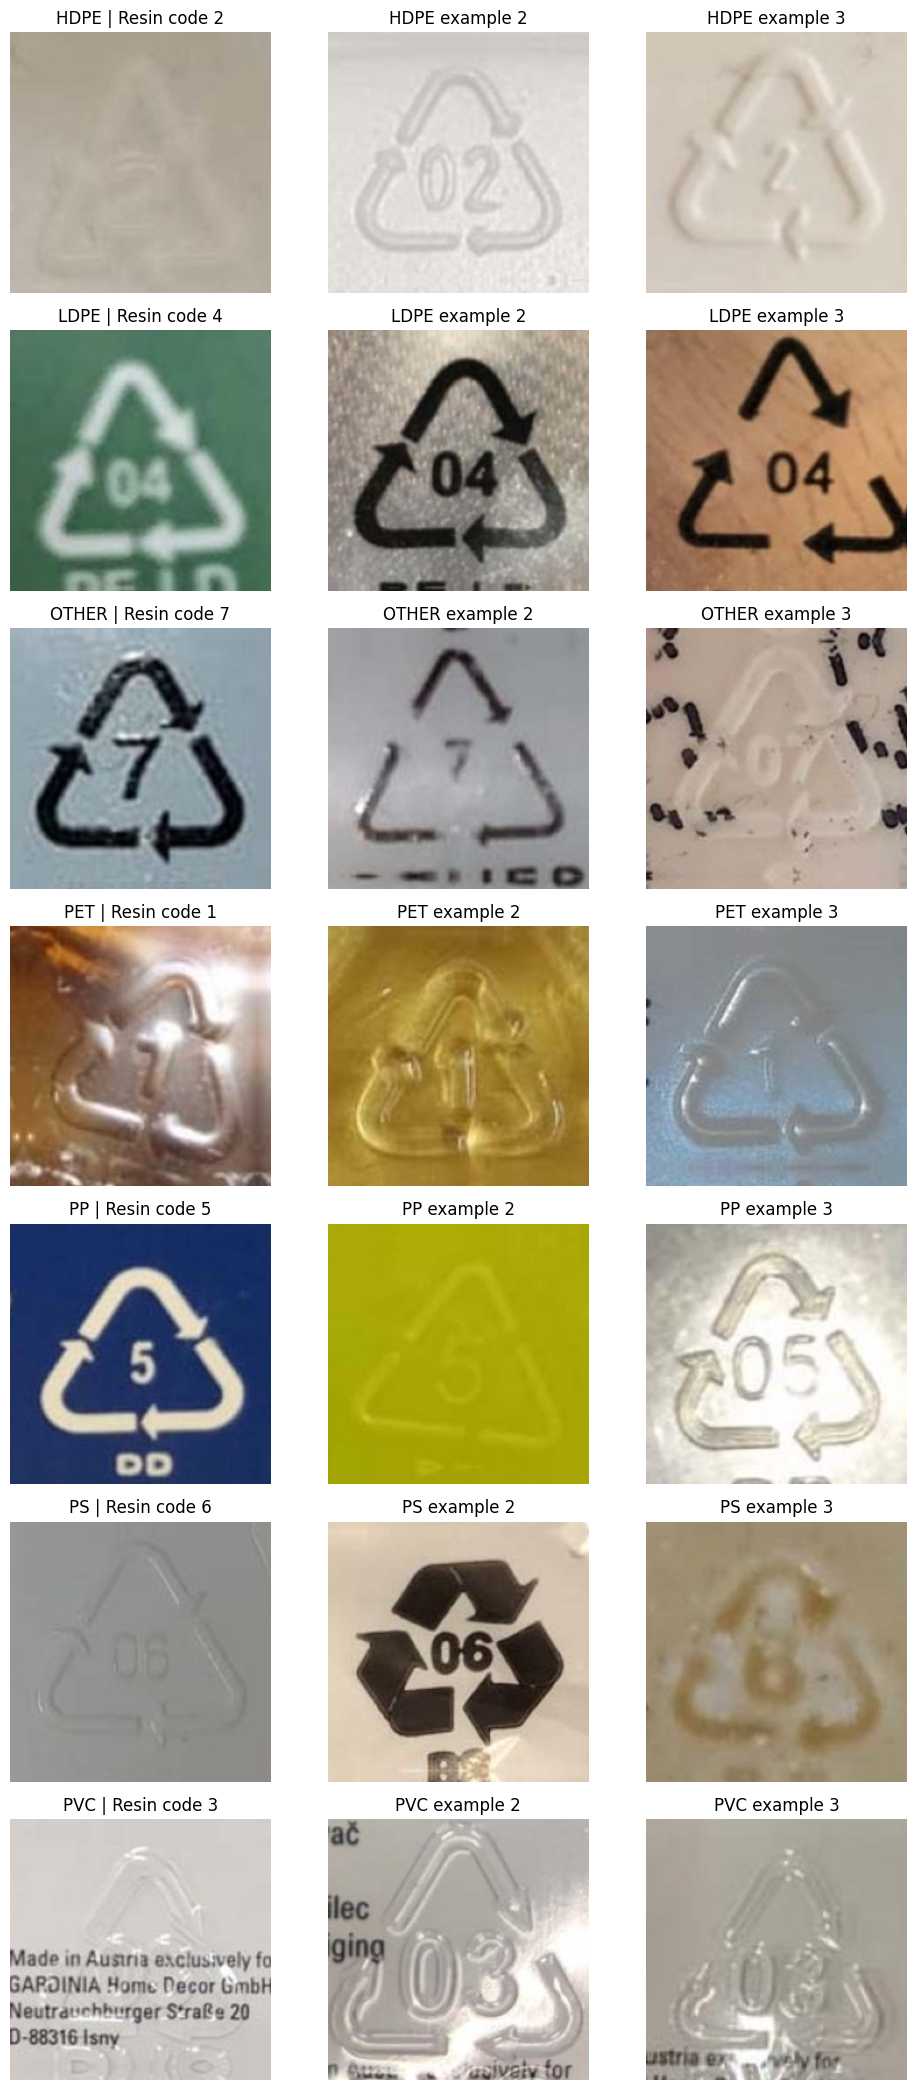

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = Path(DATA_DIR)

resin_codes = {
    "PET": 1,
    "HDPE": 2,
    "PVC": 3,
    "LDPE": 4,
    "PP": 5,
    "PS": 6,
    "OTHER": 7,
}

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

classes = sorted(
    folder.name
    for folder in (DATA_DIR / "train").iterdir()
    if folder.is_dir()
)

fig, axes = plt.subplots(
    len(classes), 3,
    figsize=(10, 3 * len(classes))
)

for row, class_name in enumerate(classes):
    files = sorted(
        path for path in (DATA_DIR / "train" / class_name).iterdir()
        if path.suffix.lower() in image_extensions
    )

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(files):
            with Image.open(files[col]) as image:
                ax.imshow(image.convert("RGB"))

            ax.set_title(
                f"{class_name} | Resin code {resin_codes[class_name]}"
                if col == 0 else f"{class_name} example {col + 1}"
            )

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

# Find the extracted classification dataset
matches = list(
    Path("/content").rglob("metadata.csv")
)

matches = [
    p for p in matches
    if all(
        (p.parent / split).is_dir()
        for split in ["train", "val", "test"]
    )
]

if not matches:
    raise FileNotFoundError(
        "Dataset not found. Please re-extract the dataset ZIP in Colab."
    )

DATA_DIR = matches[0].parent

print("Dataset path:", DATA_DIR)
print("Training images:", len(list((DATA_DIR / "train").rglob("*.*"))))
print("Validation images:", len(list((DATA_DIR / "val").rglob("*.*"))))
print("Test images:", len(list((DATA_DIR / "test").rglob("*.*"))))
print("GPU ready:", __import__("torch").cuda.is_available())

Dataset path: /content/PolymerCode-AI/data/classification_dataset/classification_dataset
Training images: 374
Validation images: 81
Test images: 81
GPU ready: True


In [ ]:
import random
import numpy as np
import torch
import pandas as pd

from pathlib import Path
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path(DATA_DIR)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ImageNet normalization: also useful for our later VGG-16 experiment
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(5),
    transforms.ColorJitter(brightness=0.10, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.ImageFolder(DATA_DIR / "train", transform=train_transform)
val_ds = datasets.ImageFolder(DATA_DIR / "val", transform=eval_transform)
test_ds = datasets.ImageFolder(DATA_DIR / "test", transform=eval_transform)

assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx

classes = train_ds.classes
num_classes = len(classes)

train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=True
)

# Moderate class weighting: reduces bias toward larger classes
counts = np.bincount(train_ds.targets, minlength=num_classes)
weights = np.sqrt(counts.sum() / (num_classes * counts))
weights = weights / weights.mean()
class_weights = torch.tensor(weights, dtype=torch.float32, device=device)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Class mapping:", train_ds.class_to_idx)
print("Training counts:", dict(zip(classes, counts.tolist())))
print("Class weights:", dict(zip(classes, weights.round(3).tolist())))
print("Batches — train:", len(train_loader), "| validation:", len(val_loader))

Device: cuda
GPU: Tesla T4
Class mapping: {'HDPE': 0, 'LDPE': 1, 'OTHER': 2, 'PET': 3, 'PP': 4, 'PS': 5, 'PVC': 6}
Training counts: {'HDPE': 51, 'LDPE': 58, 'OTHER': 42, 'PET': 74, 'PP': 114, 'PS': 21, 'PVC': 14}
Class weights: {'HDPE': 0.874, 'LDPE': 0.82, 'OTHER': 0.964, 'PET': 0.726, 'PP': 0.585, 'PS': 1.363, 'PVC': 1.669}
Batches — train: 12 | validation: 3


In [ ]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        return self.block(x)


class CustomCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),       # 224 -> 112
            ConvBlock(32, 64),      # 112 -> 56
            ConvBlock(64, 128),     # 56 -> 28
            ConvBlock(128, 256),    # 28 -> 14
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.40),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


model = CustomCNN(num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-3, weight_decay=1e-4
)

print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CustomCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, 

In [ ]:
from copy import deepcopy
from pathlib import Path
import time
import matplotlib.pyplot as plt

PROJECT_DIR = Path("/content/PolymerCode-AI")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "custom_cnn_best.pt"

MAX_EPOCHS = 30
PATIENCE = 7

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    all_true, all_pred = [], []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            predictions = logits.argmax(dim=1)

            all_true.extend(labels.detach().cpu().tolist())
            all_pred.extend(predictions.detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_f1": f1_score(
            all_true, all_pred,
            labels=list(range(num_classes)),
            average="macro",
            zero_division=0
        )
    }


history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    scheduler.step(val_metrics["loss"])

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "learning_rate": optimizer.param_groups[0]["lr"]
    }
    history.append(row)

    improved = val_metrics["loss"] < best_val_loss - 1e-4

    if improved:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_to_idx": train_ds.class_to_idx,
            "classes": classes,
            "epoch": epoch,
            "validation_loss": best_val_loss
        }, BEST_MODEL_PATH)
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val accuracy {val_metrics['accuracy']:.3f} | "
        f"val macro-F1 {val_metrics['macro_f1']:.3f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(RESULTS_DIR / "custom_cnn_training_history.csv", index=False)

# Restore the best validation-loss checkpoint
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.1f} minutes")
print("Model saved to:", BEST_MODEL_PATH)
print("History saved to:", RESULTS_DIR / "custom_cnn_training_history.csv")

Epoch 01/30 | train loss 1.9642 | val loss 1.9470 | val accuracy 0.284 | val macro-F1 0.078
Epoch 02/30 | train loss 1.8864 | val loss 1.9258 | val accuracy 0.259 | val macro-F1 0.186
Epoch 03/30 | train loss 1.8183 | val loss 1.9666 | val accuracy 0.309 | val macro-F1 0.240
Epoch 04/30 | train loss 1.7942 | val loss 1.9377 | val accuracy 0.272 | val macro-F1 0.183
Epoch 05/30 | train loss 1.7740 | val loss 1.9229 | val accuracy 0.296 | val macro-F1 0.146
Epoch 06/30 | train loss 1.7332 | val loss 1.8608 | val accuracy 0.272 | val macro-F1 0.194
Epoch 07/30 | train loss 1.7527 | val loss 2.0079 | val accuracy 0.309 | val macro-F1 0.235
Epoch 08/30 | train loss 1.7142 | val loss 1.9058 | val accuracy 0.272 | val macro-F1 0.203
Epoch 09/30 | train loss 1.7021 | val loss 2.3242 | val accuracy 0.284 | val macro-F1 0.156
Epoch 10/30 | train loss 1.7538 | val loss 1.9559 | val accuracy 0.247 | val macro-F1 0.158
Epoch 11/30 | train loss 1.6753 | val loss 1.8772 | val accuracy 0.272 | val mac

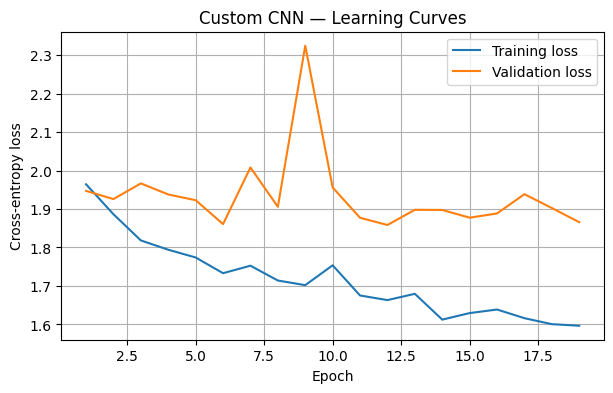

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Training loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Custom CNN — Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

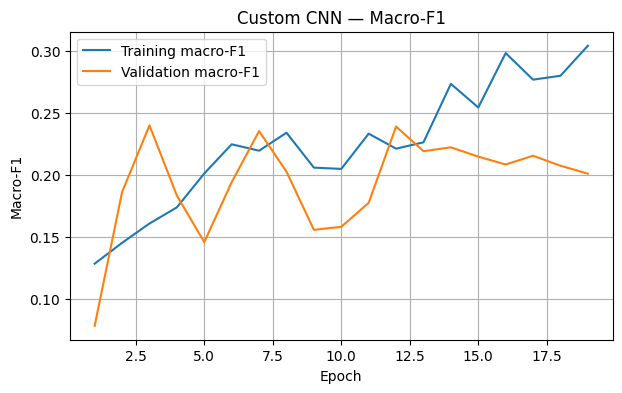

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_macro_f1"], label="Training macro-F1")
plt.plot(history_df["epoch"], history_df["val_macro_f1"], label="Validation macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Custom CNN — Macro-F1")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import time
from copy import deepcopy
from pathlib import Path

import torch
import pandas as pd
from torch import nn
from torchvision.models import vgg16, VGG16_Weights
from sklearn.metrics import accuracy_score, f1_score

assert torch.cuda.is_available(), "GPU is not available."
device = torch.device("cuda")

PROJECT_DIR = Path("/content/PolymerCode-AI")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

VGG_PATH = MODEL_DIR / "vgg16_best.pt"

# Load pretrained weights. The first run may download them.
try:
    vgg = vgg16(weights=VGG16_Weights.DEFAULT)
except Exception as e:
    raise RuntimeError(
        "Could not load pretrained VGG-16 weights. "
        "Check Colab internet access and rerun this cell."
    ) from e

# Global average pooling reduces classifier size for our small dataset.
vgg.avgpool = nn.AdaptiveAvgPool2d((1, 1))
vgg.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.4),
    nn.Linear(256, num_classes)
)

# Phase 1: freeze the pretrained convolutional feature extractor.
for param in vgg.features.parameters():
    param.requires_grad = False

vgg = vgg.to(device)
criterion_vgg = nn.CrossEntropyLoss(weight=class_weights)

def vgg_epoch(loader, training, optimizer=None):
    vgg.train(training)
    total_loss = 0.0
    targets, predictions = [], []

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = vgg(images)
            loss = criterion_vgg(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            targets.extend(labels.detach().cpu().tolist())
            predictions.extend(logits.argmax(1).detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets, predictions,
            labels=list(range(num_classes)),
            average="macro",
            zero_division=0
        )
    }

def snapshot():
    return {
        k: v.detach().cpu().clone()
        for k, v in vgg.state_dict().items()
    }

history_vgg = []
best_val_loss = float("inf")
best_state = None
start_time = time.time()

# Phase 1: train the new classifier head.
optimizer = torch.optim.AdamW(
    vgg.classifier.parameters(), lr=5e-4, weight_decay=1e-4
)

for epoch in range(1, 6):
    train_m = vgg_epoch(train_loader, True, optimizer)
    val_m = vgg_epoch(val_loader, False)

    history_vgg.append({
        "phase": "head",
        "epoch": epoch,
        "train_loss": train_m["loss"],
        "val_loss": val_m["loss"],
        "val_accuracy": val_m["accuracy"],
        "val_macro_f1": val_m["macro_f1"]
    })

    print(
        f"Head {epoch}/5 | train loss {train_m['loss']:.4f} | "
        f"val loss {val_m['loss']:.4f} | "
        f"val accuracy {val_m['accuracy']:.3f} | "
        f"val macro-F1 {val_m['macro_f1']:.3f}"
    )

    if val_m["loss"] < best_val_loss:
        best_val_loss = val_m["loss"]
        best_state = snapshot()

# Restore best head-only model before fine-tuning.
vgg.load_state_dict(best_state)

# Phase 2: fine-tune only the final VGG-16 convolutional block.
for param in vgg.features[24:].parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": vgg.features[24:].parameters(), "lr": 1e-5},
    {"params": vgg.classifier.parameters(), "lr": 1e-4}
], weight_decay=1e-4)

patience = 4
no_improvement = 0

for epoch in range(1, 11):
    train_m = vgg_epoch(train_loader, True, optimizer)
    val_m = vgg_epoch(val_loader, False)

    history_vgg.append({
        "phase": "fine_tune",
        "epoch": epoch,
        "train_loss": train_m["loss"],
        "val_loss": val_m["loss"],
        "val_accuracy": val_m["accuracy"],
        "val_macro_f1": val_m["macro_f1"]
    })

    print(
        f"Fine-tune {epoch}/10 | train loss {train_m['loss']:.4f} | "
        f"val loss {val_m['loss']:.4f} | "
        f"val accuracy {val_m['accuracy']:.3f} | "
        f"val macro-F1 {val_m['macro_f1']:.3f}"
    )

    if val_m["loss"] < best_val_loss - 1e-4:
        best_val_loss = val_m["loss"]
        best_state = snapshot()
        no_improvement = 0
    else:
        no_improvement += 1

    if no_improvement >= patience:
        print("Early stopping fine-tuning.")
        break

# Save the best checkpoint selected on validation loss.
vgg.load_state_dict(best_state)
torch.save({
    "model_state_dict": best_state,
    "class_to_idx": train_ds.class_to_idx,
    "classes": classes,
    "best_validation_loss": best_val_loss
}, VGG_PATH)

history_vgg_df = pd.DataFrame(history_vgg)
history_vgg_df.to_csv(
    RESULTS_DIR / "vgg16_training_history.csv", index=False
)

print("\nVGG-16 training complete.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.1f} minutes")
print("Checkpoint:", VGG_PATH)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 80.2MB/s]


Head 1/5 | train loss 1.8930 | val loss 1.8005 | val accuracy 0.346 | val macro-F1 0.134
Head 2/5 | train loss 1.8029 | val loss 1.7036 | val accuracy 0.395 | val macro-F1 0.196
Head 3/5 | train loss 1.7089 | val loss 1.6334 | val accuracy 0.444 | val macro-F1 0.292
Head 4/5 | train loss 1.6476 | val loss 1.5673 | val accuracy 0.444 | val macro-F1 0.323
Head 5/5 | train loss 1.5764 | val loss 1.5227 | val accuracy 0.407 | val macro-F1 0.291
Fine-tune 1/10 | train loss 1.5136 | val loss 1.4725 | val accuracy 0.420 | val macro-F1 0.275
Fine-tune 2/10 | train loss 1.4249 | val loss 1.4369 | val accuracy 0.420 | val macro-F1 0.299
Fine-tune 3/10 | train loss 1.3856 | val loss 1.4035 | val accuracy 0.469 | val macro-F1 0.344
Fine-tune 4/10 | train loss 1.3352 | val loss 1.3920 | val accuracy 0.481 | val macro-F1 0.360
Fine-tune 5/10 | train loss 1.2774 | val loss 1.3888 | val accuracy 0.506 | val macro-F1 0.384
Fine-tune 6/10 | train loss 1.2317 | val loss 1.3789 | val accuracy 0.481 | val 

In [ ]:
from torchvision import datasets
from torch.utils.data import DataLoader

# Create the held-out test dataset
test_ds = datasets.ImageFolder(
    DATA_DIR / "test",
    transform=eval_transform
)

# Verify the same class-to-index mapping
assert test_ds.class_to_idx == train_ds.class_to_idx, (
    "Class mappings do not match!"
)

# Create the missing test loader
test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test loader created successfully!")
print("Test images:", len(test_ds))
print("Test batches:", len(test_loader))
print("Classes:", test_ds.class_to_idx)

Test loader created successfully!
Test images: 81
Test batches: 3
Classes: {'HDPE': 0, 'LDPE': 1, 'OTHER': 2, 'PET': 3, 'PP': 4, 'PS': 5, 'PVC': 6}



=============== Custom CNN ===============
Test accuracy: 0.3580
Test macro-F1: 0.2532


,precision,recall,f1-score,support
HDPE,0.333,0.778,0.467,9.0
LDPE,0.333,0.467,0.389,15.0
OTHER,0.500,0.091,0.154,11.0
PET,0.438,0.467,0.452,15.0
PP,0.333,0.292,0.311,24.0
PS,0.000,0.000,0.000,4.0
PVC,0.000,0.000,0.000,3.0


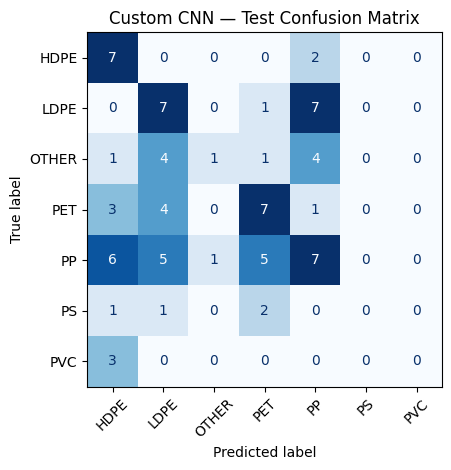


=============== VGG-16 ===============
Test accuracy: 0.6173
Test macro-F1: 0.5436


,precision,recall,f1-score,support
HDPE,1.000,0.556,0.714,9.0
LDPE,0.600,0.800,0.686,15.0
OTHER,0.571,0.364,0.444,11.0
PET,0.600,0.800,0.686,15.0
PP,0.636,0.583,0.609,24.0
PS,0.000,0.000,0.000,4.0
PVC,0.500,1.000,0.667,3.0


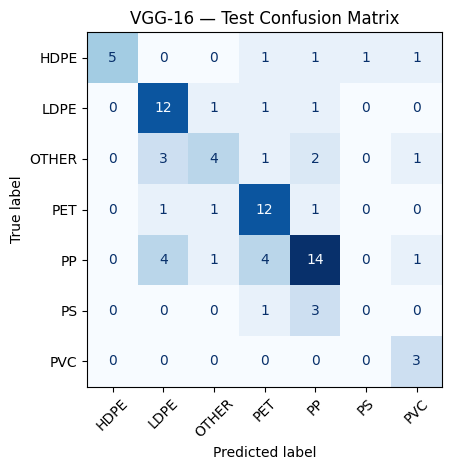


FINAL MODEL COMPARISON


,Model,Test Accuracy,Test Macro-F1
0,Custom CNN,0.3580,0.2532
1,VGG-16,0.6173,0.5436


Comparison saved successfully.


In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from torchvision.models import vgg16, VGG16_Weights

# Load the saved best Custom CNN
cnn_checkpoint = torch.load(
    MODEL_DIR / "custom_cnn_best.pt",
    map_location=device,
    weights_only=False
)

cnn = CustomCNN(num_classes=len(classes)).to(device)
cnn.load_state_dict(cnn_checkpoint["model_state_dict"])
cnn.eval()

# Rebuild VGG-16 with the same architecture used during training
vgg = vgg16(weights=None)
vgg.avgpool = torch.nn.AdaptiveAvgPool2d((1, 1))
vgg.classifier = torch.nn.Sequential(
    torch.nn.Linear(512, 256),
    torch.nn.ReLU(inplace=True),
    torch.nn.Dropout(0.4),
    torch.nn.Linear(256, len(classes))
)
vgg = vgg.to(device)

vgg_checkpoint = torch.load(
    MODEL_DIR / "vgg16_best.pt",
    map_location=device,
    weights_only=False
)
vgg.load_state_dict(vgg_checkpoint["model_state_dict"])
vgg.eval()

assert cnn_checkpoint["class_to_idx"] == test_ds.class_to_idx
assert vgg_checkpoint["class_to_idx"] == test_ds.class_to_idx

def predict_all(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            predictions = model(images).argmax(dim=1)

            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())

    return y_true, y_pred

# Evaluate both models on the exact same test set
y_true, cnn_pred = predict_all(cnn, test_loader)
y_true_vgg, vgg_pred = predict_all(vgg, test_loader)
assert y_true == y_true_vgg

comparison_rows = []

for model_name, predictions in [
    ("Custom CNN", cnn_pred),
    ("VGG-16", vgg_pred),
]:
    acc = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(
        y_true, predictions,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )

    comparison_rows.append({
        "Model": model_name,
        "Test Accuracy": acc,
        "Test Macro-F1": macro_f1
    })

    print(f"\n{'=' * 15} {model_name} {'=' * 15}")
    print(f"Test accuracy: {acc:.4f}")
    print(f"Test macro-F1: {macro_f1:.4f}")

    report = classification_report(
        y_true,
        predictions,
        labels=list(range(len(classes))),
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    display(pd.DataFrame(report).T.loc[
        classes, ["precision", "recall", "f1-score", "support"]
    ].round(3))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=list(range(len(classes))),
        display_labels=classes,
        xticks_rotation=45,
        cmap="Blues",
        colorbar=False
    )
    plt.title(f"{model_name} — Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

comparison = pd.DataFrame(comparison_rows)
print("\nFINAL MODEL COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    RESULTS_DIR / "final_test_comparison.csv",
    index=False
)
print("Comparison saved successfully.")

In [ ]:
from pathlib import Path
import shutil
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Mount Google Drive
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/PolymerCode-AI")
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR = PROJECT_DIR / "models"

DRIVE_DIR = Path("/content/drive/MyDrive/PolymerCode-AI")
DRIVE_MODELS = DRIVE_DIR / "models"
DRIVE_RESULTS = DRIVE_DIR / "results"

DRIVE_MODELS.mkdir(parents=True, exist_ok=True)
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

# Save detailed reports from the already completed test evaluation.
for model_name, predictions in [
    ("custom_cnn", cnn_pred),
    ("vgg16", vgg_pred),
]:
    report = classification_report(
        y_true,
        predictions,
        labels=list(range(len(classes))),
        target_names=classes,
        output_dict=True,
        zero_division=0,
    )

    pd.DataFrame(report).T.to_csv(
        RESULTS_DIR / f"{model_name}_test_report.csv"
    )

    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=list(range(len(classes))),
        display_labels=classes,
        xticks_rotation=45,
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{model_name} — Test Confusion Matrix")
    fig.tight_layout()
    fig.savefig(
        RESULTS_DIR / f"{model_name}_confusion_matrix.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.close(fig)

# Copy models and results to persistent Google Drive.
for folder, destination in [
    (MODEL_DIR, DRIVE_MODELS),
    (RESULTS_DIR, DRIVE_RESULTS),
]:
    for file in folder.iterdir():
        if file.is_file():
            shutil.copy2(file, destination / file.name)

print("Saved project artifacts to:", DRIVE_DIR)
print("Model files:")
for file in sorted(DRIVE_MODELS.iterdir()):
    print(f"  {file.name}: {file.stat().st_size / (1024**2):.1f} MB")

print("\nResult files:")
for file in sorted(DRIVE_RESULTS.iterdir()):
    print(" ", file.name)

Mounted at /content/drive
Saved project artifacts to: /content/drive/MyDrive/PolymerCode-AI
Model files:
  custom_cnn_best.pt: 4.6 MB
  vgg16_best.pt: 56.6 MB

Result files:
  custom_cnn_confusion_matrix.png
  custom_cnn_test_report.csv
  custom_cnn_training_history.csv
  final_test_comparison.csv
  vgg16_confusion_matrix.png
  vgg16_test_report.csv
  vgg16_training_history.csv


VGG-16 validation classification report:
              precision    recall  f1-score   support

        HDPE       0.71      0.56      0.62         9
        LDPE       0.45      0.67      0.54        15
       OTHER       0.50      0.44      0.47         9
         PET       0.60      0.80      0.69        15
          PP       0.67      0.50      0.57        24
          PS       0.00      0.00      0.00         6
         PVC       0.00      0.00      0.00         3

    accuracy                           0.53        81
   macro avg       0.42      0.42      0.41        81
weighted avg       0.53      0.53      0.52        81


Validation confusion matrix:


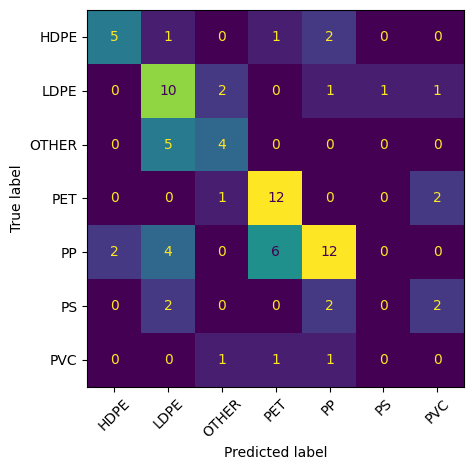


Actual validation counts:
PP       24
PET      15
LDPE     15
OTHER     9
HDPE      9
PS        6
PVC       3
Name: count, dtype: int64

Predicted validation counts:
LDPE     22
PET      20
PP       18
OTHER     8
HDPE      7
PVC       5
PS        1
Name: count, dtype: int64


In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate the validation loader without augmentation
val_ds = datasets.ImageFolder(
    DATA_DIR / "val",
    transform=eval_transform
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Load our saved best VGG-16 checkpoint
checkpoint = torch.load(
    MODEL_DIR / "vgg16_best.pt",
    map_location=device,
    weights_only=False
)

# The same architecture used during training
from torchvision.models import vgg16
from torch import nn

vgg = vgg16(weights=None)
vgg.avgpool = nn.AdaptiveAvgPool2d((1, 1))
vgg.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.4),
    nn.Linear(256, len(classes))
)

vgg.load_state_dict(checkpoint["model_state_dict"])
vgg = vgg.to(device)
vgg.eval()

assert checkpoint["class_to_idx"] == val_ds.class_to_idx

y_true_val = []
y_pred_val = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(device)
        predictions = vgg(images).argmax(dim=1)

        y_true_val.extend(labels.tolist())
        y_pred_val.extend(predictions.cpu().tolist())

print("VGG-16 validation classification report:")
print(classification_report(
    y_true_val,
    y_pred_val,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

print("\nValidation confusion matrix:")
ConfusionMatrixDisplay.from_predictions(
    y_true_val,
    y_pred_val,
    labels=list(range(len(classes))),
    display_labels=classes,
    xticks_rotation=45,
    colorbar=False
)
plt.tight_layout()
plt.show()

print("\nActual validation counts:")
print(pd.Series(y_true_val).map(dict(enumerate(classes))).value_counts())

print("\nPredicted validation counts:")
print(pd.Series(y_pred_val).map(dict(enumerate(classes))).value_counts())

TRAIN — PS: 21 images
VAL — PS: 6 images
TRAIN — PVC: 14 images
VAL — PVC: 3 images


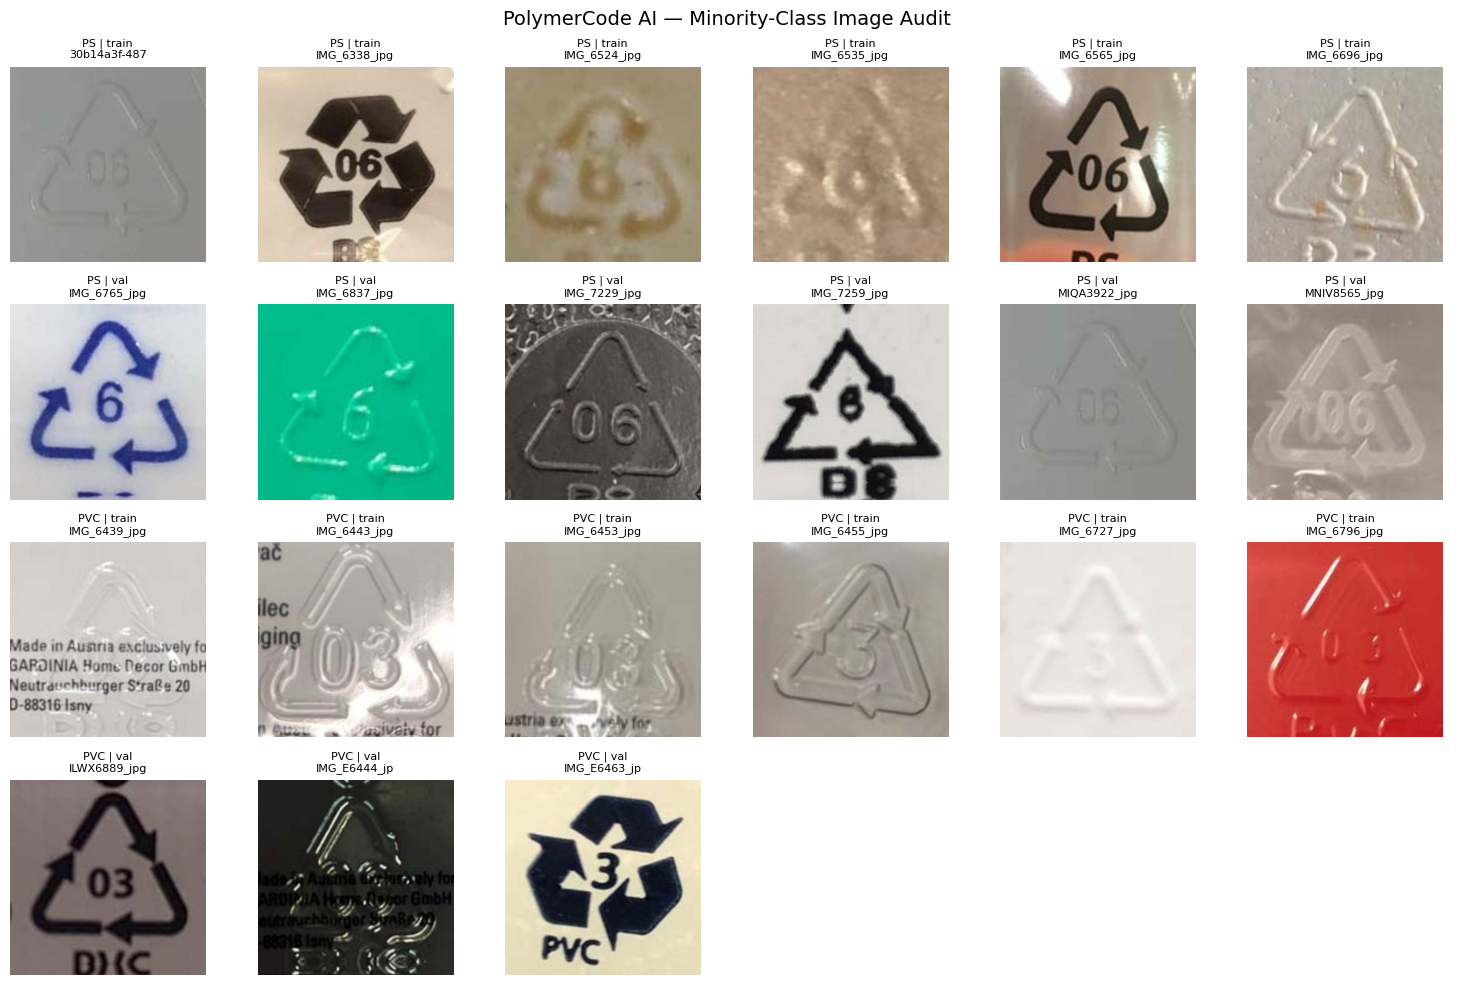

In [ ]:
from pathlib import Path
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

classes_to_check = ["PS", "PVC"]
splits_to_check = ["train", "val"]

fig, axes = plt.subplots(4, 6, figsize=(15, 10))

for i, class_name in enumerate(classes_to_check):
    for j, split in enumerate(splits_to_check):
        row = i * 2 + j

        image_dir = DATA_DIR / split / class_name
        image_files = sorted([
            p for p in image_dir.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
        ])

        print(f"{split.upper()} — {class_name}: {len(image_files)} images")

        # Show up to six examples from this class and split
        for col in range(6):
            ax = axes[row, col]
            ax.axis("off")

            if col < len(image_files):
                with Image.open(image_files[col]) as im:
                    im = ImageOps.exif_transpose(im).convert("RGB")
                    ax.imshow(im)

                ax.set_title(
                    f"{class_name} | {split}\n{image_files[col].name[:12]}",
                    fontsize=8
                )

plt.suptitle("PolymerCode AI — Minority-Class Image Audit", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
import pandas as pd

counts = Counter(train_ds.targets)

class_audit = pd.DataFrame([
    {
        "Class": class_name,
        "Resin code": {
            "PET": 1, "HDPE": 2, "PVC": 3,
            "LDPE": 4, "PP": 5, "PS": 6, "OTHER": 7
        }[class_name],
        "Training images": counts[idx],
        "Share (%)": round(100 * counts[idx] / len(train_ds), 2)
    }
    for class_name, idx in train_ds.class_to_idx.items()
])

display(class_audit.sort_values("Training images"))

print(
    "Largest/smallest class ratio:",
    round(max(counts.values()) / min(counts.values()), 2)
)

,Class,Resin code,Training images,Share (%)
6,PVC,3,14,3.74
5,PS,6,21,5.61
2,OTHER,7,42,11.23
0,HDPE,2,51,13.64
1,LDPE,4,58,15.51
3,PET,1,74,19.79
4,PP,5,114,30.48


Largest/smallest class ratio: 8.14


Training classes: {'HDPE': 51, 'LDPE': 58, 'OTHER': 42, 'PET': 74, 'PP': 114, 'PS': 21, 'PVC': 14}
Balanced sampling enabled for TRAINING only.
Validation images: 81
Epoch 1/8 | train loss 1.1252 | val loss 1.3121 | val accuracy 0.506 | val macro-F1 0.400
Epoch 2/8 | train loss 1.0342 | val loss 1.2903 | val accuracy 0.506 | val macro-F1 0.398
Epoch 3/8 | train loss 1.0681 | val loss 1.3088 | val accuracy 0.506 | val macro-F1 0.397
Epoch 4/8 | train loss 0.9489 | val loss 1.2890 | val accuracy 0.531 | val macro-F1 0.441
Epoch 5/8 | train loss 0.9698 | val loss 1.2906 | val accuracy 0.531 | val macro-F1 0.440
Epoch 6/8 | train loss 0.9247 | val loss 1.2610 | val accuracy 0.519 | val macro-F1 0.406
Epoch 7/8 | train loss 0.9684 | val loss 1.2687 | val accuracy 0.531 | val macro-F1 0.413
Early stopping: validation macro-F1 did not improve.

Balanced VGG-16 experiment complete.
Best validation macro-F1: 0.4413
Best epoch: 4
Elapsed minutes: 0.37
Checkpoint: /content/PolymerCode-AI/models/v

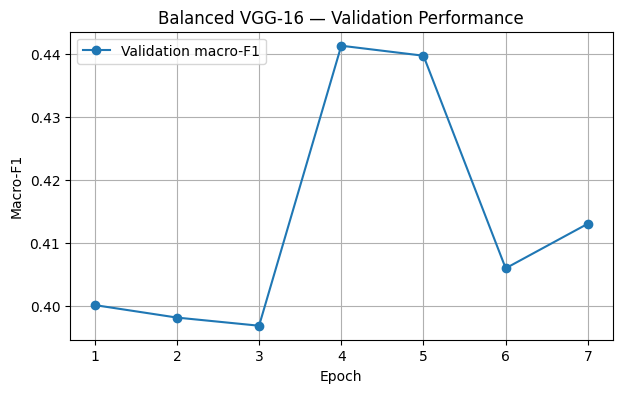

In [ ]:
import time
import copy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from torch import nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_DIR = Path("/content/PolymerCode-AI")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Re-create datasets, preserving train-only augmentation.
train_ds_bal = datasets.ImageFolder(
    DATA_DIR / "train",
    transform=train_transform
)
val_ds_bal = datasets.ImageFolder(
    DATA_DIR / "val",
    transform=eval_transform
)

assert train_ds_bal.class_to_idx == val_ds_bal.class_to_idx

classes_bal = train_ds_bal.classes
num_classes_bal = len(classes_bal)

# --------------------------------------------------
# 2. Moderately balanced sampling
# --------------------------------------------------
counts = np.bincount(
    train_ds_bal.targets,
    minlength=num_classes_bal
)

# Inverse-square-root weighting is less aggressive
# than giving every class exactly equal probability.
sample_weights = [
    1.0 / np.sqrt(counts[label])
    for label in train_ds_bal.targets
]

sampler_generator = torch.Generator().manual_seed(SEED)

balanced_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(train_ds_bal),
    replacement=True,
    generator=sampler_generator
)

train_loader_bal = DataLoader(
    train_ds_bal,
    batch_size=32,
    sampler=balanced_sampler,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader_bal = DataLoader(
    val_ds_bal,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training classes:", dict(zip(classes_bal, counts.tolist())))
print("Balanced sampling enabled for TRAINING only.")
print("Validation images:", len(val_ds_bal))

# --------------------------------------------------
# 3. Restore the original best VGG-16 checkpoint
# --------------------------------------------------
checkpoint = torch.load(
    MODEL_DIR / "vgg16_best.pt",
    map_location="cpu",
    weights_only=False
)

assert checkpoint["class_to_idx"] == train_ds_bal.class_to_idx

vgg_bal = models.vgg16(weights=None)
vgg_bal.avgpool = nn.AdaptiveAvgPool2d((1, 1))
vgg_bal.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.4),
    nn.Linear(256, num_classes_bal)
)

vgg_bal.load_state_dict(checkpoint["model_state_dict"])

# Freeze all convolutional layers initially.
for param in vgg_bal.features.parameters():
    param.requires_grad = False

# Fine-tune only the final convolutional block.
for param in vgg_bal.features[24:].parameters():
    param.requires_grad = True

vgg_bal = vgg_bal.to(device)

# IMPORTANT: sampling is already rebalancing exposure.
# Use ordinary cross-entropy, not a second class-weighting scheme.
criterion_bal = nn.CrossEntropyLoss()

optimizer_bal = torch.optim.AdamW(
    [
        {
            "params": vgg_bal.features[24:].parameters(),
            "lr": 5e-6
        },
        {
            "params": vgg_bal.classifier.parameters(),
            "lr": 5e-5
        }
    ],
    weight_decay=1e-4
)

# --------------------------------------------------
# 4. Training and validation functions
# --------------------------------------------------
def run_balanced_epoch(loader, training):
    vgg_bal.train(training)

    total_loss = 0.0
    y_true_epoch, y_pred_epoch = [], []

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer_bal.zero_grad(set_to_none=True)

            logits = vgg_bal(images)
            loss = criterion_bal(logits, labels)

            if training:
                loss.backward()
                optimizer_bal.step()

            total_loss += loss.item() * len(labels)
            y_true_epoch.extend(labels.detach().cpu().tolist())
            y_pred_epoch.extend(
                logits.argmax(dim=1).detach().cpu().tolist()
            )

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(y_true_epoch, y_pred_epoch),
        "macro_f1": f1_score(
            y_true_epoch,
            y_pred_epoch,
            labels=list(range(num_classes_bal)),
            average="macro",
            zero_division=0
        )
    }

def save_balanced_checkpoint(epoch, macro_f1, val_loss):
    torch.save(
        {
            "model_state_dict": {
                k: v.detach().cpu().clone()
                for k, v in vgg_bal.state_dict().items()
            },
            "class_to_idx": train_ds_bal.class_to_idx,
            "classes": classes_bal,
            "epoch": epoch,
            "validation_macro_f1": macro_f1,
            "validation_loss": val_loss,
        },
        MODEL_DIR / "vgg16_balanced_best.pt"
    )

# --------------------------------------------------
# 5. Train with early stopping on validation macro-F1
# --------------------------------------------------
history_bal = []
best_macro_f1 = -1.0
best_epoch_bal = 0
patience = 3
stale_epochs = 0
max_epochs = 8

start_time = time.time()

for epoch in range(1, max_epochs + 1):
    train_m = run_balanced_epoch(train_loader_bal, True)
    val_m = run_balanced_epoch(val_loader_bal, False)

    row = {
        "epoch": epoch,
        "train_loss": train_m["loss"],
        "train_macro_f1": train_m["macro_f1"],
        "val_loss": val_m["loss"],
        "val_accuracy": val_m["accuracy"],
        "val_macro_f1": val_m["macro_f1"],
    }
    history_bal.append(row)

    print(
        f"Epoch {epoch}/{max_epochs} | "
        f"train loss {train_m['loss']:.4f} | "
        f"val loss {val_m['loss']:.4f} | "
        f"val accuracy {val_m['accuracy']:.3f} | "
        f"val macro-F1 {val_m['macro_f1']:.3f}"
    )

    if val_m["macro_f1"] > best_macro_f1 + 1e-4:
        best_macro_f1 = val_m["macro_f1"]
        best_epoch_bal = epoch
        stale_epochs = 0
        save_balanced_checkpoint(
            epoch,
            val_m["macro_f1"],
            val_m["loss"]
        )
    else:
        stale_epochs += 1

    if stale_epochs >= patience:
        print("Early stopping: validation macro-F1 did not improve.")
        break

history_bal_df = pd.DataFrame(history_bal)
history_bal_df.to_csv(
    RESULTS_DIR / "vgg16_balanced_history.csv",
    index=False
)

print("\nBalanced VGG-16 experiment complete.")
print("Best validation macro-F1:", round(best_macro_f1, 4))
print("Best epoch:", best_epoch_bal)
print("Elapsed minutes:", round((time.time() - start_time) / 60, 2))
print("Checkpoint:", MODEL_DIR / "vgg16_balanced_best.pt")

plt.figure(figsize=(7, 4))
plt.plot(
    history_bal_df["epoch"],
    history_bal_df["val_macro_f1"],
    marker="o",
    label="Validation macro-F1"
)
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Balanced VGG-16 — Validation Performance")
plt.grid(True)
plt.legend()
plt.show()


===== Original VGG-16 — Validation =====
Accuracy: 0.5309
Macro-F1: 0.4133


,precision,recall,f1-score,support
HDPE,0.714,0.556,0.625,9.0
LDPE,0.455,0.667,0.541,15.0
OTHER,0.500,0.444,0.471,9.0
PET,0.600,0.800,0.686,15.0
PP,0.667,0.500,0.571,24.0
PS,0.000,0.000,0.000,6.0
PVC,0.000,0.000,0.000,3.0


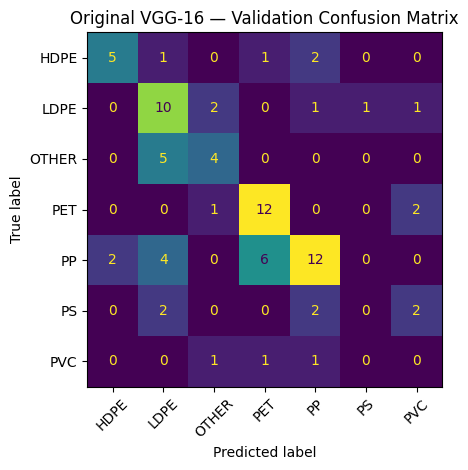


===== Balanced VGG-16 — Validation =====
Accuracy: 0.5309
Macro-F1: 0.4413


,precision,recall,f1-score,support
HDPE,0.714,0.556,0.625,9.0
LDPE,0.455,0.667,0.541,15.0
OTHER,0.500,0.444,0.471,9.0
PET,0.571,0.800,0.667,15.0
PP,0.733,0.458,0.564,24.0
PS,0.333,0.167,0.222,6.0
PVC,0.000,0.000,0.000,3.0


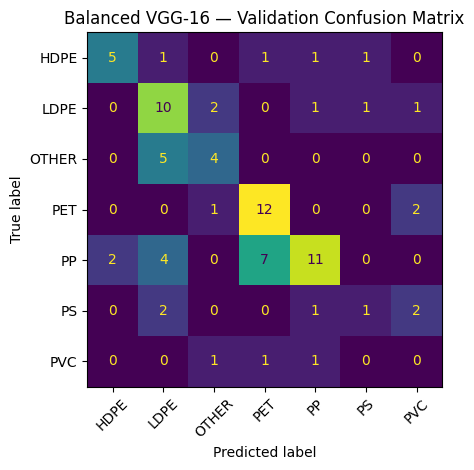

In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

from torch import nn
from torchvision.models import vgg16
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_vgg():
    model = vgg16(weights=None)
    model.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    model.classifier = nn.Sequential(
        nn.Linear(512, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.4),
        nn.Linear(256, len(classes))
    )
    return model.to(device)

def load_vgg_checkpoint(path):
    checkpoint = torch.load(
        path, map_location=device, weights_only=False
    )
    assert checkpoint["class_to_idx"] == val_ds.class_to_idx

    model = build_vgg()
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model

def predict_validation(model, loader):
    y_true, y_pred = [], []

    model.eval()
    with torch.inference_mode():
        for images, labels in loader:
            logits = model(images.to(device))
            y_pred.extend(logits.argmax(1).cpu().tolist())
            y_true.extend(labels.tolist())

    return y_true, y_pred

original_vgg = load_vgg_checkpoint(MODEL_DIR / "vgg16_best.pt")
balanced_vgg = load_vgg_checkpoint(
    MODEL_DIR / "vgg16_balanced_best.pt"
)

y_val, pred_original = predict_validation(original_vgg, val_loader_bal)
y_val_bal, pred_balanced = predict_validation(balanced_vgg, val_loader_bal)

assert y_val == y_val_bal

for name, predictions in [
    ("Original VGG-16", pred_original),
    ("Balanced VGG-16", pred_balanced),
]:
    print(f"\n===== {name} — Validation =====")

    print("Accuracy:", round(accuracy_score(y_val, predictions), 4))
    print("Macro-F1:", round(f1_score(
        y_val, predictions,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    ), 4))

    report = classification_report(
        y_val,
        predictions,
        labels=list(range(len(classes))),
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    display(pd.DataFrame(report).T.loc[
        classes, ["precision", "recall", "f1-score", "support"]
    ].round(3))

    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        labels=list(range(len(classes))),
        display_labels=classes,
        xticks_rotation=45,
        colorbar=False
    )
    plt.title(f"{name} — Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [ ]:
from google.colab import drive

drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
NOTEBOOK_NAME = "PolymerCode_AI_ANN_Project.ipynb"

In [ ]:
# Locate the notebook you're currently using in Colab
DRIVE = Path("/content/drive/MyDrive")

NOTEBOOK_SOURCE = DRIVE / "Colab Notebooks" / "Untitled19.ipynb"

if not NOTEBOOK_SOURCE.exists():
    raise FileNotFoundError(
        f"Notebook not found: {NOTEBOOK_SOURCE}"
    )

print("Notebook found:", NOTEBOOK_SOURCE)

Notebook found: /content/drive/MyDrive/Colab Notebooks/Untitled19.ipynb


In [32]:
# ============================================================
# PolymerCode AI — AUTOMATIC PROJECT PACKAGER
# Run this complete cell once in Google Colab.
# ============================================================

from pathlib import Path
import shutil
import json
import pickle
import zipfile
import textwrap
import hashlib
import torch
import pandas as pd

# -------------------- 1. Mount Google Drive --------------------
from google.colab import drive, files

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

DRIVE = Path("/content/drive/MyDrive")
SOURCE_PROJECT = Path("/content/PolymerCode-AI")

print("Preparing PolymerCode AI project...")

# -------------------- 2. Locate notebook automatically --------------------
preferred_notebook = (
    DRIVE / "Colab Notebooks" / "Untitled19.ipynb"
)

if preferred_notebook.exists():
    NOTEBOOK_SOURCE = preferred_notebook
else:
    candidates = list(DRIVE.rglob("*.ipynb"))
    matching = [
        p for p in candidates
        if p.name.lower().replace(" ", "").replace("_", "")
        in {
            "untitled19.ipynb",
            "untitled119.ipynb",
            "polymercodeaiannproject.ipynb",
        }
    ]

    if not matching:
        raise FileNotFoundError(
            "Could not find Untitled19.ipynb in Google Drive. "
            "Save your current notebook to Drive and rerun this cell."
        )

    NOTEBOOK_SOURCE = matching[0]

print("Notebook found:", NOTEBOOK_SOURCE)

# -------------------- 3. Locate dataset automatically --------------------
def is_dataset_folder(path):
    return (
        path.is_dir()
        and all((path / s).is_dir() for s in ("train", "val", "test"))
        and (path / "metadata.csv").is_file()
    )

data_variable = globals().get("DATA_DIR")
if data_variable is not None and is_dataset_folder(Path(data_variable)):
    DATA_SOURCE = Path(data_variable)
else:
    matches = [
        p.parent for p in Path("/content").rglob("metadata.csv")
        if is_dataset_folder(p.parent)
    ]
    if not matches:
        raise FileNotFoundError(
            "Could not find the extracted classification dataset."
        )
    DATA_SOURCE = matches[0]

print("Dataset found:", DATA_SOURCE)

# -------------------- 4. Verify model checkpoints --------------------
MODEL_SOURCE = SOURCE_PROJECT / "models"
RESULT_SOURCE = SOURCE_PROJECT / "results"

required_models = [
    "custom_cnn_best.pt",
    "vgg16_best.pt",
    "vgg16_balanced_best.pt",
]

missing = [
    name for name in required_models
    if not (MODEL_SOURCE / name).is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing model files: " + ", ".join(missing)
        + "\nExpected location: " + str(MODEL_SOURCE)
        + "\nDo not retrain yet; check where the checkpoints were saved."
    )

# -------------------- 5. Create clean project folder --------------------
RELEASE = Path("/content/PolymerCode-AI-Release")
DRIVE_RELEASE = DRIVE / "PolymerCode-AI-Release"
ZIP_PATH = Path("/content/PolymerCode-AI-Release.zip")
DRIVE_ZIP = DRIVE / "PolymerCode-AI-Release.zip"

# Remove only the previous generated release, not your training project.
for path in (RELEASE, DRIVE_RELEASE):
    if path.exists():
        shutil.rmtree(path)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

folders = [
    "notebooks",
    "data/raw",
    "data/processed",
    "models",
    "results",
    "src",
    "frontend",
    "backend",
]

for folder in folders:
    (RELEASE / folder).mkdir(parents=True, exist_ok=True)

# -------------------- 6. Copy notebook and dataset --------------------
shutil.copy2(
    NOTEBOOK_SOURCE,
    RELEASE / "notebooks" / "PolymerCode_AI_ANN_Project.ipynb",
)

shutil.copytree(
    DATA_SOURCE,
    RELEASE / "data/processed/classification_dataset",
    dirs_exist_ok=True,
)

# Retain a matching source ZIP in data/raw, if present.
for archive in Path("/content").glob("*.zip"):
    if "plastic_recycle_sign" in archive.name.lower():
        shutil.copy2(archive, RELEASE / "data/raw" / archive.name)

print("Notebook and dataset copied.")

# -------------------- 7. Export checkpoints and PKL bundles --------------------
# PKL bundles contain weights/configuration, not entire pickled model objects.
resin_codes = {
    "PET": 1,
    "HDPE": 2,
    "PVC": 3,
    "LDPE": 4,
    "PP": 5,
    "PS": 6,
    "OTHER": 7,
}

model_specs = [
    ("custom_cnn", "custom_cnn_best.pt", "custom_cnn"),
    ("vgg16", "vgg16_best.pt", "vgg16"),
    ("vgg16_balanced", "vgg16_balanced_best.pt", "vgg16"),
]

manifest = {
    "project": "PolymerCode AI",
    "course": "Artificial Neural Networks (ANN)",
    "dataset": {
        "image_crops": 536,
        "class_count": 7,
        "split_counts": {"train": 374, "val": 81, "test": 81},
        "resin_codes": resin_codes,
    },
    "preprocessing": {
        "input_size": [224, 224],
        "color_mode": "RGB",
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225],
        "note": "Softmax scores are not calibrated probabilities.",
    },
    "models": {},
    "reported_results": {
        "custom_cnn_test": {
            "accuracy": 0.3580,
            "macro_f1": 0.2532,
        },
        "vgg16_test": {
            "accuracy": 0.6173,
            "macro_f1": 0.5436,
        },
        "vgg16_original_validation": {
            "accuracy": 0.5309,
            "macro_f1": 0.4133,
        },
        "vgg16_balanced_validation": {
            "accuracy": 0.5309,
            "macro_f1": 0.4413,
        },
        "vgg16_balanced_test": {
            "status": "Not evaluated",
        },
    },
}

for artifact_name, filename, architecture in model_specs:
    source = MODEL_SOURCE / filename
    checkpoint = torch.load(
        source, map_location="cpu", weights_only=False
    )

    # Keep original PyTorch checkpoint.
    shutil.copy2(source, RELEASE / "models" / filename)

    # Prepare portable configuration + weights PKL bundle.
    bundle = {
        "format": "PolymerCodeAI-state-dict-v1",
        "architecture": architecture,
        "model_state_dict": {
            k: v.detach().cpu() if torch.is_tensor(v) else v
            for k, v in checkpoint["model_state_dict"].items()
        },
        "classes": checkpoint["classes"],
        "class_to_idx": checkpoint["class_to_idx"],
        "resin_codes": resin_codes,
        "input_size": [224, 224],
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225],
        "checkpoint_metadata": {
            k: v for k, v in checkpoint.items()
            if k != "model_state_dict"
        },
    }

    pkl_path = RELEASE / "models" / f"{artifact_name}.pkl"
    with open(pkl_path, "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

    manifest["models"][artifact_name] = {
        "checkpoint": filename,
        "pkl_bundle": pkl_path.name,
        "architecture": architecture,
        "class_to_idx": checkpoint["class_to_idx"],
    }

with open(RELEASE / "models/model_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Three checkpoints and three PKL bundles exported.")

# -------------------- 8. Copy results and notebook artifacts --------------------
if RESULT_SOURCE.exists():
    for item in RESULT_SOURCE.rglob("*"):
        if item.is_file():
            relative = item.relative_to(RESULT_SOURCE)
            destination = RELEASE / "results" / relative
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(item, destination)

# Include current final-test reports if they exist in notebook memory.
if all(k in globals() for k in ("y_true", "cnn_pred", "vgg_pred", "classes")):
    from sklearn.metrics import classification_report, ConfusionMatrixDisplay
    import matplotlib.pyplot as plt

    for name, predictions in (
        ("custom_cnn", cnn_pred),
        ("original_vgg16", vgg_pred),
    ):
        report = classification_report(
            y_true,
            predictions,
            labels=list(range(len(classes))),
            target_names=classes,
            output_dict=True,
            zero_division=0,
        )

        pd.DataFrame(report).T.to_csv(
            RELEASE / "results" / f"{name}_test_report.csv"
        )

        fig, ax = plt.subplots(figsize=(7, 6))
        ConfusionMatrixDisplay.from_predictions(
            y_true,
            predictions,
            labels=list(range(len(classes))),
            display_labels=classes,
            xticks_rotation=45,
            colorbar=False,
            ax=ax,
        )
        ax.set_title(f"{name} — Test Confusion Matrix")
        fig.tight_layout()
        fig.savefig(
            RELEASE / "results" / f"{name}_confusion_matrix.png",
            dpi=180,
            bbox_inches="tight",
        )
        plt.close(fig)

# -------------------- 9. Reusable model architecture code --------------------
architecture_code = r'''
from torch import nn
from torchvision.models import vgg16

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

    def forward(self, x):
        return self.block(x)

class CustomCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
            ConvBlock(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.40),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def build_vgg16(num_classes=7):
    model = vgg16(weights=None)
    model.avgpool = nn.AdaptiveAvgPool2d((1, 1))
    model.classifier = nn.Sequential(
        nn.Linear(512, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.4),
        nn.Linear(256, num_classes),
    )
    return model
'''

(RELEASE / "src/model_architectures.py").write_text(
    textwrap.dedent(architecture_code).strip() + "\n",
    encoding="utf-8",
)
(RELEASE / "src/__init__.py").write_text("", encoding="utf-8")

# -------------------- 10. Create setup and handoff files --------------------
(RELEASE / "requirements.txt").write_text(
    "\n".join([
        "torch",
        "torchvision",
        "numpy",
        "pandas",
        "scikit-learn",
        "matplotlib",
        "Pillow",
        "streamlit",
        "fastapi",
        "uvicorn",
    ]) + "\n",
    encoding="utf-8",
)

(RELEASE / "frontend/README.md").write_text(
    "# Frontend\n\nReserved for frontend development in Antigravity.\n",
    encoding="utf-8",
)
(RELEASE / "backend/README.md").write_text(
    "# Backend\n\nReserved for prediction API and inference integration in Antigravity.\n",
    encoding="utf-8",
)

(RELEASE / "DATASET_ATTRIBUTION.txt").write_text(
    "Dataset source: Plastic Recycle Sign — Anthony, Roboflow Universe\n"
    "https://universe.roboflow.com/anthony-q0mmp/plastic_recycle_sign\n"
    "The source page identifies a CC BY 4.0 license. Retain attribution "
    "and comply with the applicable license terms when redistributing.\n",
    encoding="utf-8",
)

(RELEASE / "README.md").write_text(
    """# PolymerCode AI

Artificial Neural Networks (ANN) course project for plastic resin-code
classification from images.

## Package contents
- notebooks/: complete Colab notebook
- data/processed/classification_dataset/: image crops, splits and metadata
- models/: three PyTorch checkpoints and three PKL state-dict bundles
- models/model_manifest.json: class mapping and model configuration
- src/: reusable model architecture definitions
- results/: available training histories, reports and plots
- frontend/ and backend/: placeholders for Antigravity implementation

## Resin codes
PET=1, HDPE=2, PVC=3, LDPE=4, PP=5, PS=6, OTHER=7.

## Checkpoints
- custom_cnn_best.pt / custom_cnn.pkl
- vgg16_best.pt / vgg16.pkl
- vgg16_balanced_best.pt / vgg16_balanced.pkl

The PT checkpoints are the primary PyTorch artifacts. The PKL files hold
state dictionaries and configuration, not complete serialized model objects.
Rebuild the matching architecture from src/model_architectures.py before
loading weights. Only load pickle files from trusted sources.

## Reported initial results
Custom CNN test: accuracy 35.80%, macro-F1 0.2532.
Original VGG-16 test: accuracy 61.73%, macro-F1 0.5436.
Balanced VGG-16 validation macro-F1: 0.4413.
The balanced VGG-16 has not yet been evaluated on the test set.

The dataset contains 536 crops and seven classes. PS and PVC have few
examples, so their evaluation scores are uncertain. Model scores are not
calibrated probabilities and predictions may be incorrect.
""",
    encoding="utf-8",
)

# -------------------- 11. Build project ZIP --------------------
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for item in RELEASE.rglob("*"):
        if item.is_file():
            archive.write(
                item,
                Path("PolymerCode-AI-Release") / item.relative_to(RELEASE)
            )

# Persistent Drive folder and ZIP.
shutil.copytree(RELEASE, DRIVE_RELEASE)
shutil.copy2(ZIP_PATH, DRIVE_ZIP)

# -------------------- 12. Verify package --------------------
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_member = archive.testzip()
    if bad_member:
        raise RuntimeError(f"ZIP verification failed at: {bad_member}")

print("\n" + "=" * 55)
print("PROJECT PACKAGE CREATED SUCCESSFULLY")
print("=" * 55)
print("Colab folder :", RELEASE)
print("Google Drive :", DRIVE_RELEASE)
print("ZIP file     :", ZIP_PATH)
print("Drive ZIP    :", DRIVE_ZIP)
print("ZIP size MB  :", round(ZIP_PATH.stat().st_size / (1024**2), 2))
print("\nTop-level files:")
for item in sorted(RELEASE.iterdir()):
    print(" -", item.name)

print("\nStarting ZIP download...")
files.download(str(ZIP_PATH))

Preparing PolymerCode AI project...
Notebook found: /content/drive/MyDrive/Colab Notebooks/Untitled19.ipynb
Dataset found: /content/PolymerCode-AI/data/classification_dataset/classification_dataset
Notebook and dataset copied.
Three checkpoints and three PKL bundles exported.

PROJECT PACKAGE CREATED SUCCESSFULLY
Colab folder : /content/PolymerCode-AI-Release
Google Drive : /content/drive/MyDrive/PolymerCode-AI-Release
ZIP file     : /content/PolymerCode-AI-Release.zip
Drive ZIP    : /content/drive/MyDrive/PolymerCode-AI-Release.zip
ZIP size MB  : 227.39

Top-level files:
 - DATASET_ATTRIBUTION.txt
 - README.md
 - backend
 - data
 - frontend
 - models
 - notebooks
 - requirements.txt
 - results
 - src

Starting ZIP download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>